<a href="https://colab.research.google.com/github/SushrutKerulkar/charts-analysis-evidence-for-week-3/blob/main/Charts_%26_Analysis_Evidence_for_Week_3_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

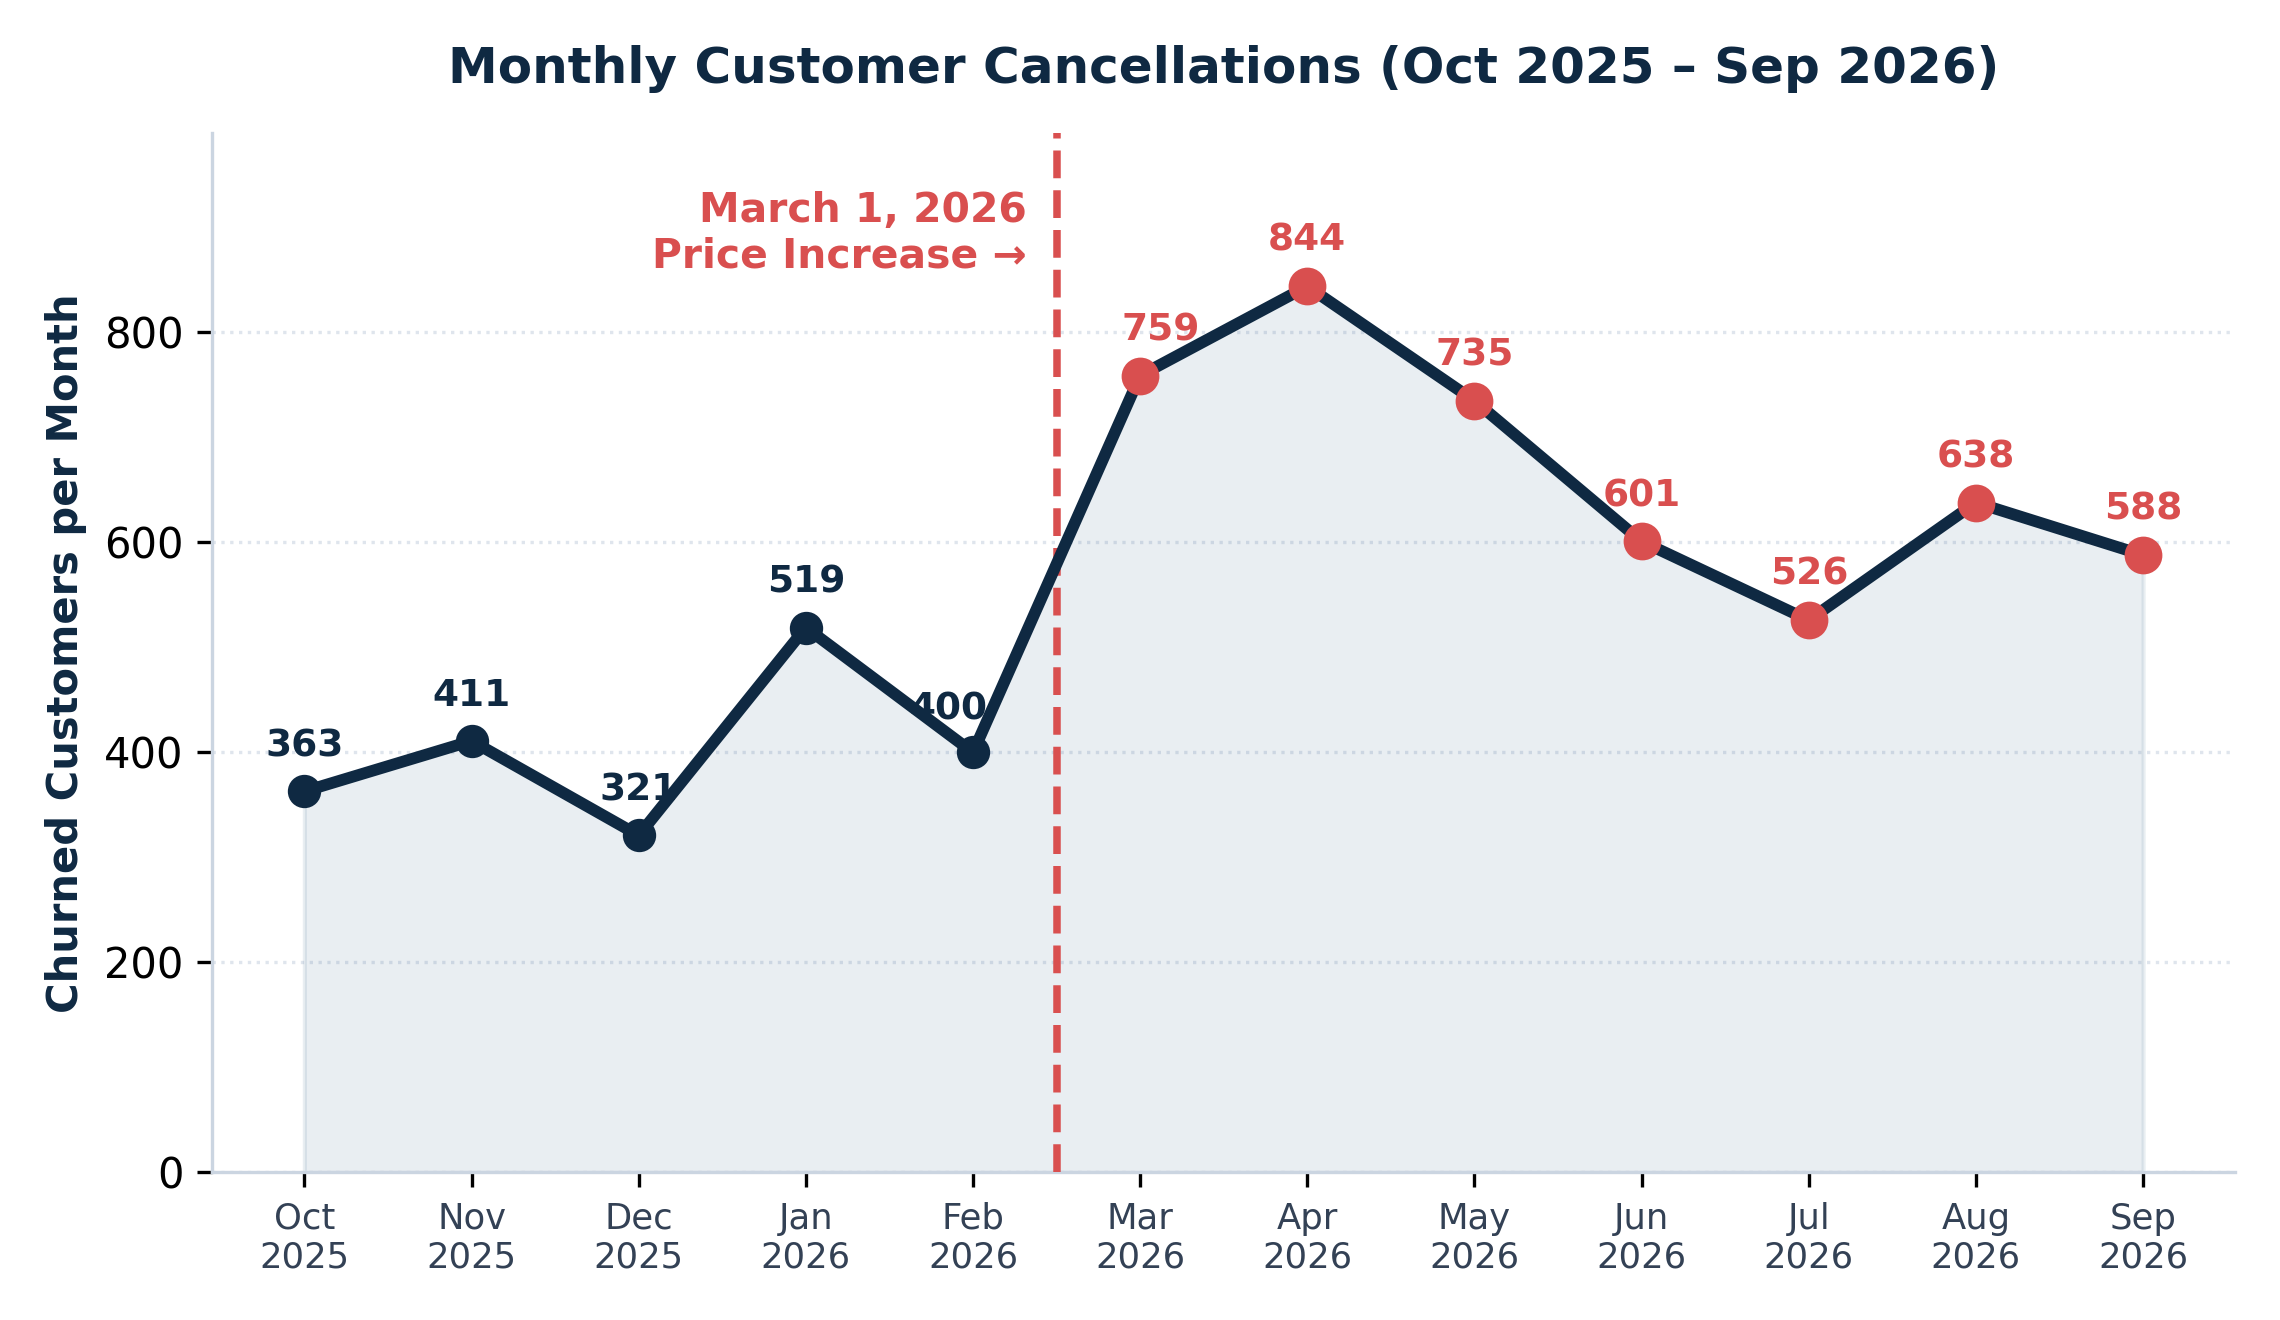

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Image, display

# ---------------------------------------------------------
# Setup & Data Loading
# ---------------------------------------------------------
os.makedirs('charts', exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8

NAVY = '#0F2942'
SLATE = '#2B5B84'
CORAL = '#D94F4F'
TEAL = '#1E8C7A'
AMBER = '#E09F3E'
GRAY = '#64748B'
BG = '#FFFFFF'

xls = pd.ExcelFile('Telco_Customer_Churn_Dataset_v2.xlsx')
df = pd.read_excel(xls, sheet_name='Customers')
df['Churn_num'] = (df['Churn'] == 'Yes').astype(int)

# ---------------------------------------------------------
# CHART 1 (Slide 4): Cancellations Doubled After March Hike
# Monthly Churn Trend (Oct 2025 – Sep 2026)
# ---------------------------------------------------------
df['ChurnMonth'] = pd.to_datetime(df['ChurnDate']).dt.to_period('M')
monthly = df['ChurnMonth'].value_counts().sort_index()
months_short = [pd.Period(m).strftime('%b\n%Y') for m in monthly.index]
vals = monthly.values

fig, ax = plt.subplots(figsize=(7.6, 4.4), dpi=300)
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

ax.plot(range(len(vals)), vals, color=NAVY, linewidth=2.8, marker='o', markersize=7, zorder=4)
ax.fill_between(range(len(vals)), vals, color=SLATE, alpha=0.10, zorder=2)

ax.scatter(range(5, len(vals)), vals[5:], color=CORAL, s=65, zorder=5)
ax.axvline(x=4.5, color=CORAL, linestyle='--', linewidth=1.8, zorder=3)
ax.text(4.32, 935, 'March 1, 2026\nPrice Increase →', color=CORAL,
        fontsize=9.8, fontweight='bold', va='top', ha='right')

for i, v in enumerate(vals):
    dx = -0.15 if i == 4 else (0.12 if i == 5 else 0.0)
    dy = 24 if i == 4 else 26
    color = CORAL if i >= 5 else NAVY
    ax.text(i + dx, v + dy, f'{v:,}', ha='center', va='bottom',
            fontsize=9, fontweight='bold', color=color)

ax.set_xticks(range(len(vals)))
ax.set_xticklabels(months_short, fontsize=8.5, color='#334155')
ax.set_ylim(0, 990)
ax.set_ylabel('Churned Customers per Month', fontsize=10, fontweight='bold', color=NAVY)
ax.set_title('Monthly Customer Cancellations (Oct 2025 – Sep 2026)',
             fontsize=12, fontweight='bold', color=NAVY, pad=12)
ax.grid(axis='y', linestyle=':', alpha=0.6, color='#CBD5E1')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('charts/monthly_churn.png', dpi=300, facecolor=BG)
plt.close()


display(Image('charts/monthly_churn.png'))

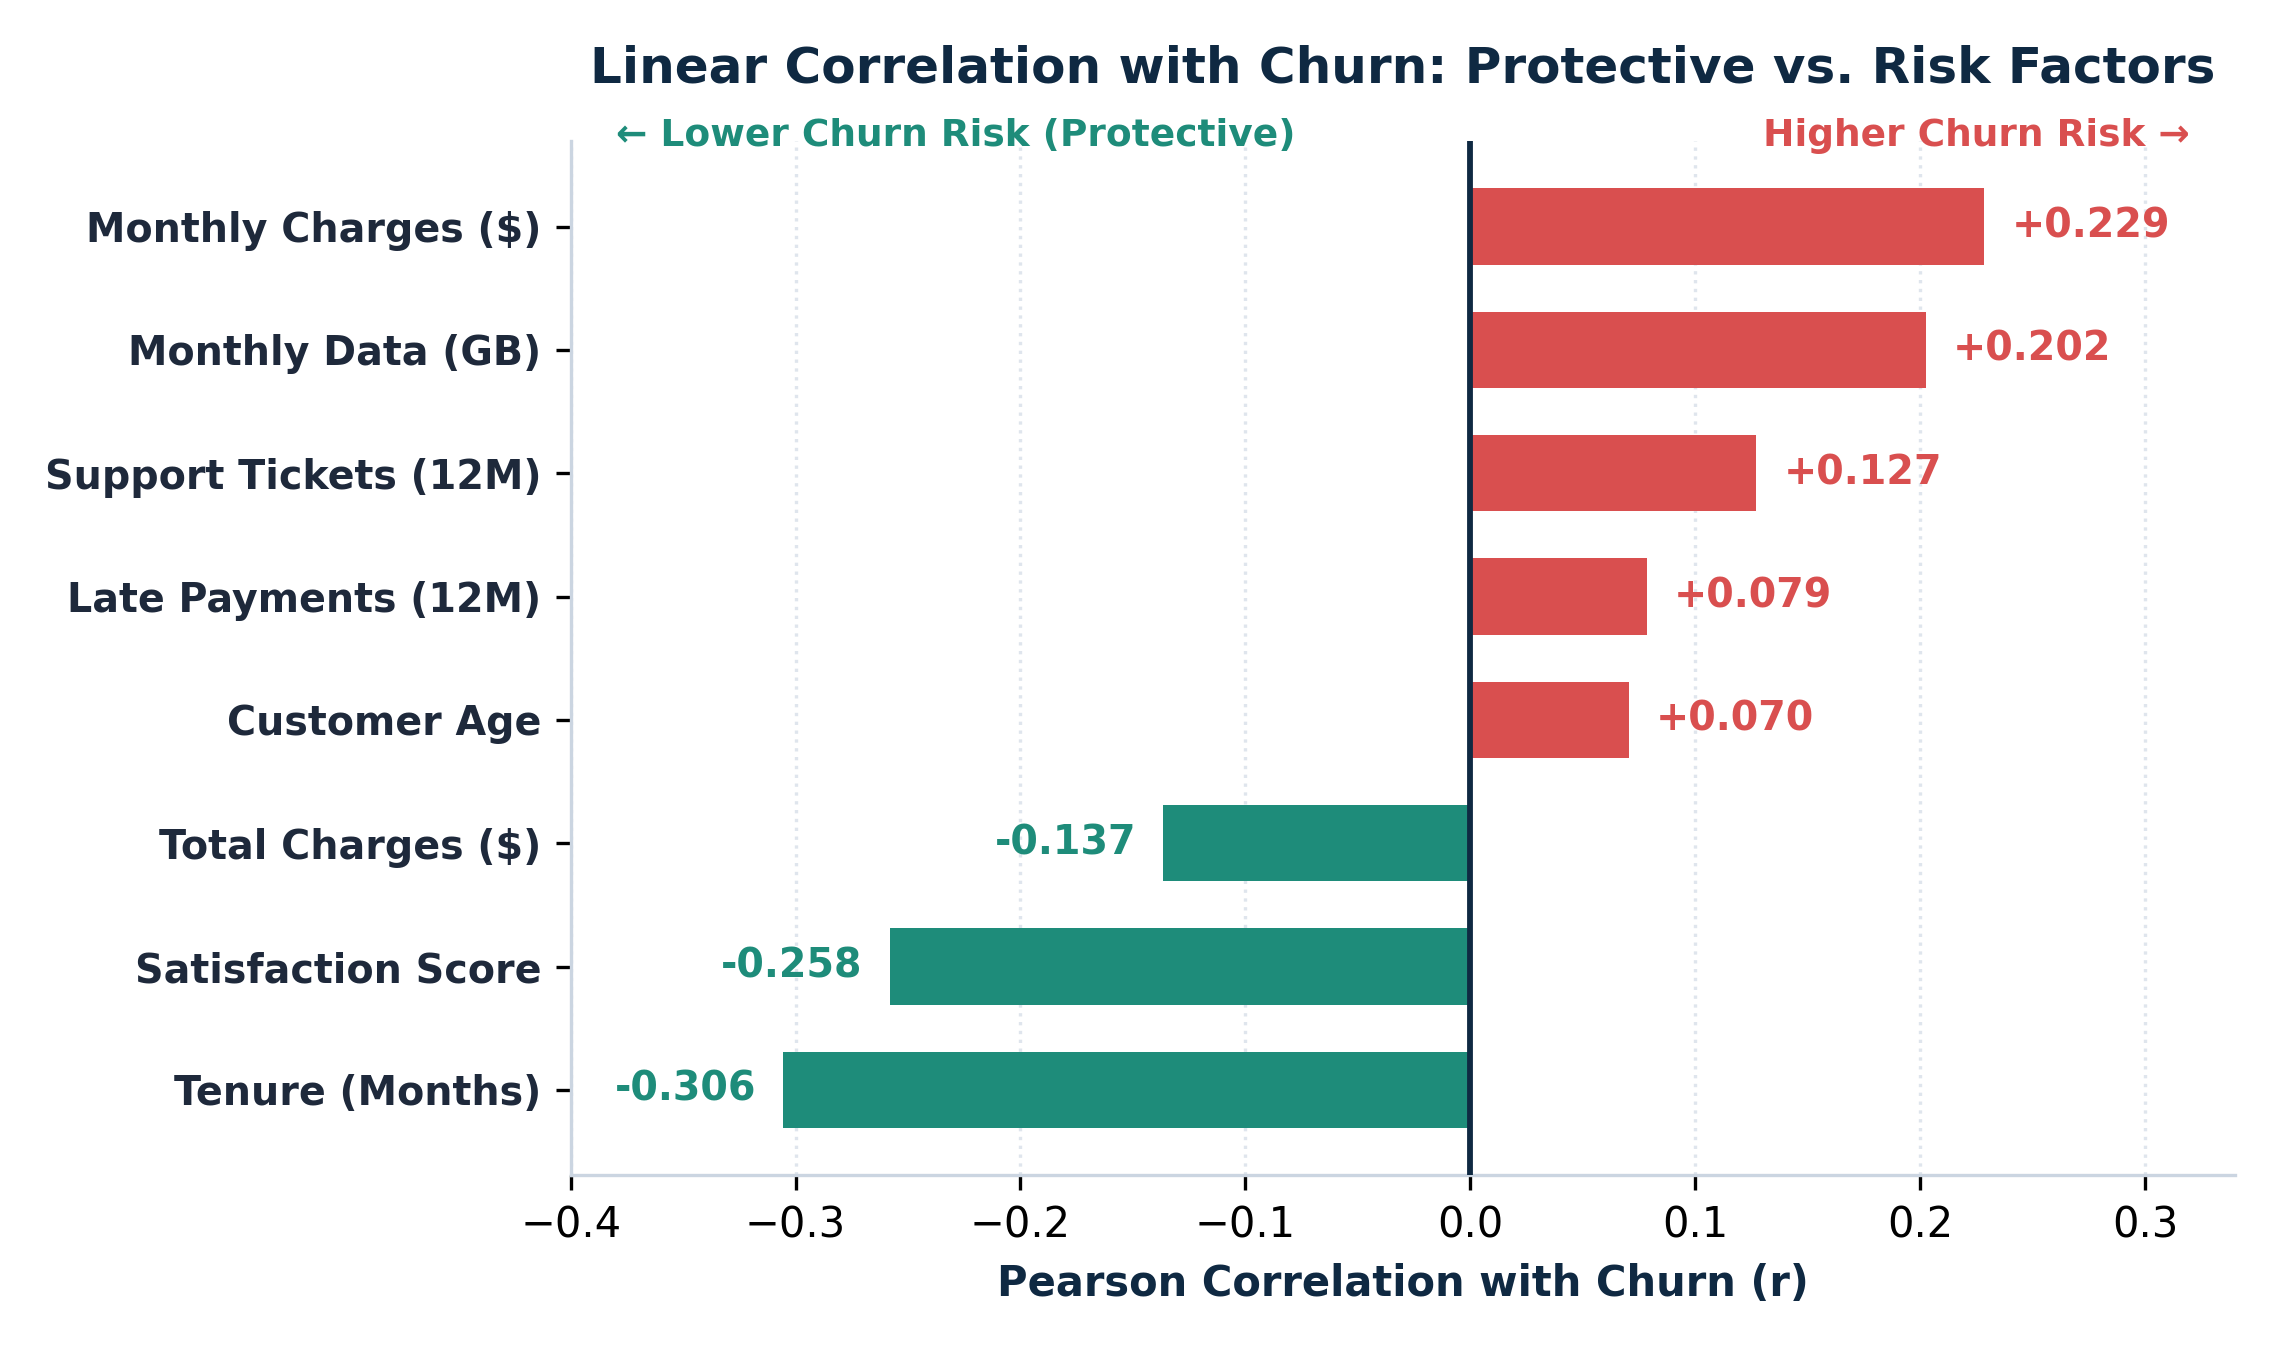

In [2]:
# ---------------------------------------------------------
# CHART 2 (Slide 6): Churn Drivers: Protective vs. Risk (r)
# ---------------------------------------------------------
num_cols = [
    'TenureMonths', 'SatisfactionScore', 'TotalCharges', 'Age',
    'LatePayments12M', 'SupportTickets12M', 'MonthlyDataGB', 'MonthlyCharges'
]
pretty_names = {
    'TenureMonths': 'Tenure (Months)',
    'SatisfactionScore': 'Satisfaction Score',
    'TotalCharges': 'Total Charges ($)',
    'Age': 'Customer Age',
    'LatePayments12M': 'Late Payments (12M)',
    'SupportTickets12M': 'Support Tickets (12M)',
    'MonthlyDataGB': 'Monthly Data (GB)',
    'MonthlyCharges': 'Monthly Charges ($)'
}
corrs = df[num_cols + ['Churn_num']].corr()['Churn_num'].drop('Churn_num').sort_values()

fig, ax = plt.subplots(figsize=(7.6, 4.5), dpi=300)
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

colors = [TEAL if v < 0 else CORAL for v in corrs.values]
y_pos = np.arange(len(corrs))
ax.barh(y_pos, corrs.values, color=colors, height=0.62, edgecolor='none', zorder=3)

ax.axvline(0, color=NAVY, linewidth=1.4, zorder=4)
ax.set_yticks(y_pos)
ax.set_yticklabels([pretty_names[c] for c in corrs.index],
                   fontsize=9.5, fontweight='bold', color='#1E293B')
ax.set_xlim(-0.40, 0.34)
ax.set_xlabel('Pearson Correlation with Churn (r)', fontsize=10, fontweight='bold', color=NAVY)
ax.set_title('Linear Correlation with Churn: Protective vs. Risk Factors',
             fontsize=12, fontweight='bold', color=NAVY, pad=14)

for i, v in enumerate(corrs.values):
    if v < 0:
        ax.text(v - 0.012, i, f'{v:.3f}', ha='right', va='center',
                fontsize=9.5, fontweight='bold', color=TEAL)
    else:
        ax.text(v + 0.012, i, f'+{v:.3f}', ha='left', va='center',
                fontsize=9.5, fontweight='bold', color=CORAL)

ax.text(-0.38, 7.65, '← Lower Churn Risk (Protective)', color=TEAL,
        fontsize=9, fontweight='bold', ha='left')
ax.text(0.32, 7.65, 'Higher Churn Risk →', color=CORAL,
        fontsize=9, fontweight='bold', ha='right')

ax.grid(axis='x', linestyle=':', alpha=0.6, color='#CBD5E1', zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('charts/correlations.png', dpi=300, facecolor=BG)
plt.close()

display(Image('charts/correlations.png'))

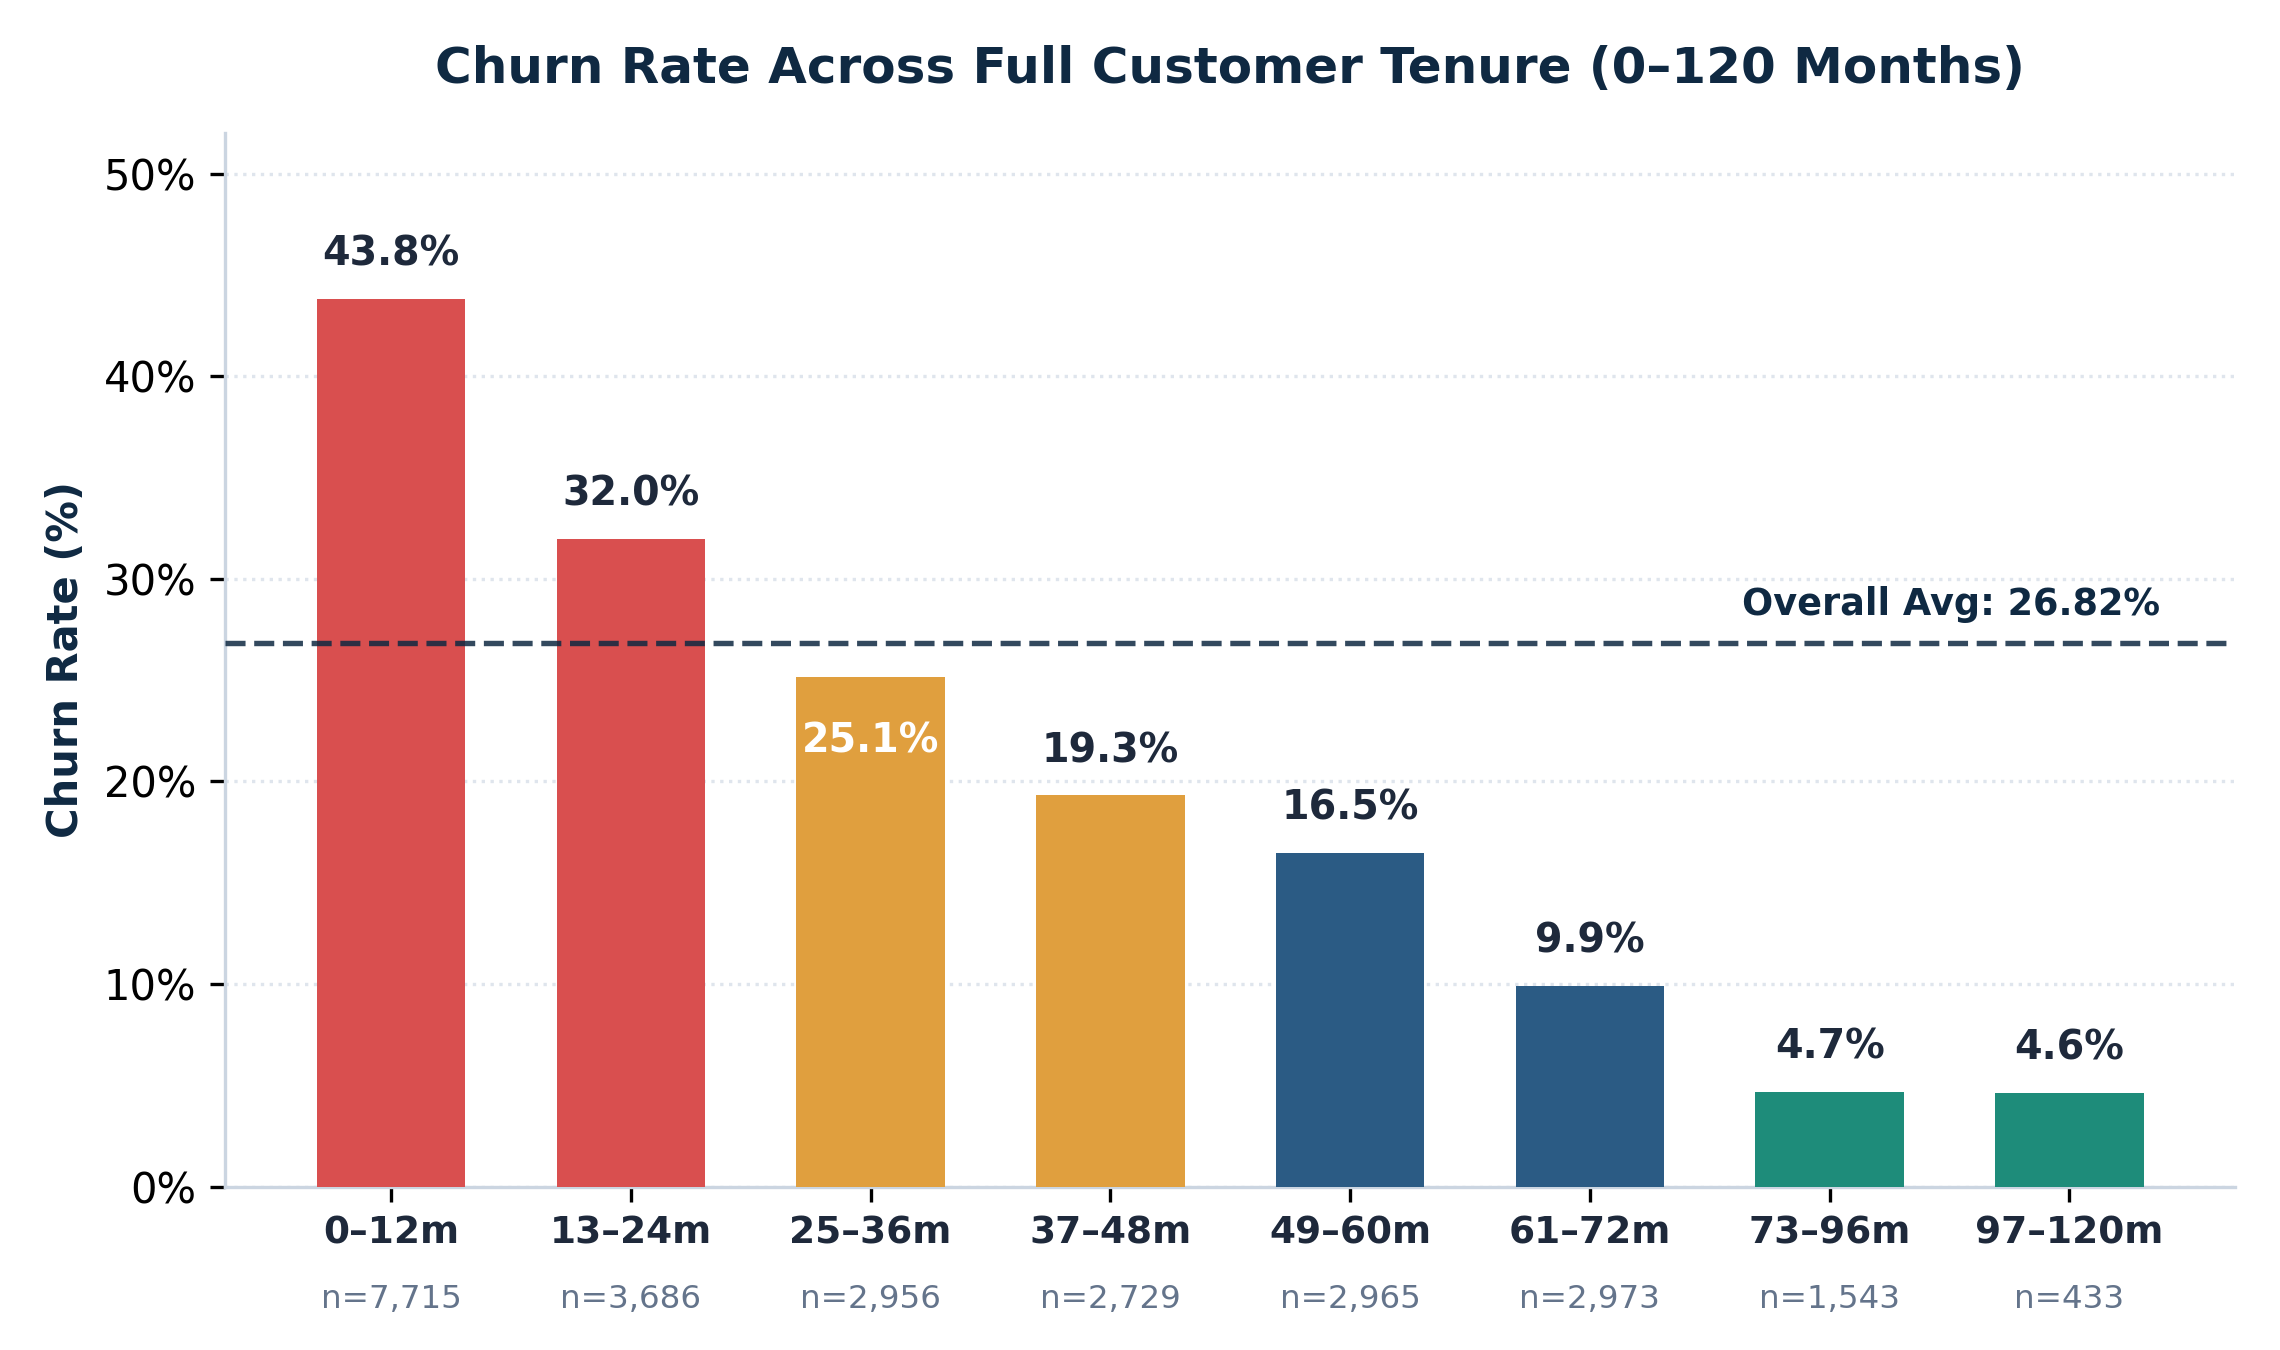

In [3]:
# ---------------------------------------------------------
# CHART 3 (Slide 8): Churn Across Full 120-Month Tenure
# ---------------------------------------------------------
bins = [-1, 12, 24, 36, 48, 60, 72, 96, 120]
labels = ['0–12m', '13–24m', '25–36m', '37–48m', '49–60m', '61–72m', '73–96m', '97–120m']
df['TenureBucket'] = pd.cut(df['TenureMonths'], bins=bins, labels=labels)
ten_grp = df.groupby('TenureBucket', observed=False).agg(
    Count=('CustomerID', 'count'),
    ChurnRate=('Churn_num', lambda x: x.mean() * 100)
)

fig, ax = plt.subplots(figsize=(7.6, 4.5), dpi=300)
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

bar_colors = [
    CORAL if r >= 30 else (AMBER if r >= 18 else (SLATE if r >= 8 else TEAL))
    for r in ten_grp['ChurnRate']
]
x_pos = np.arange(len(labels))
ax.bar(x_pos, ten_grp['ChurnRate'], color=bar_colors, width=0.62, zorder=3)

for i, (rate, cnt) in enumerate(zip(ten_grp['ChurnRate'], ten_grp['Count'])):
    if i == 2:  # Keep 25.1% label cleanly inside bar away from the 26.82% avg line
        ax.text(i, rate - 2.2, f'{rate:.1f}%', ha='center', va='top',
                fontsize=9.5, fontweight='bold', color='white', zorder=5)
    else:
        ax.text(i, rate + 1.2, f'{rate:.1f}%', ha='center', va='bottom',
                fontsize=9.5, fontweight='bold', color='#1E293B', zorder=5)
    ax.text(i, -4.8, f'n={cnt:,}', ha='center', va='top', fontsize=7.8, color=GRAY)

ax.axhline(26.82, color=NAVY, linestyle='--', linewidth=1.3, alpha=0.85, zorder=4)
ax.text(7.38, 27.8, 'Overall Avg: 26.82%', ha='right', va='bottom',
        fontsize=8.8, fontweight='bold', color=NAVY)

ax.set_xticks(x_pos)
ax.set_xticklabels(labels, fontsize=9, fontweight='bold', color='#1E293B')
ax.set_ylim(0, 52)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Churn Rate (%)', fontsize=10, fontweight='bold', color=NAVY)
ax.set_title('Churn Rate Across Full Customer Tenure (0–120 Months)',
             fontsize=12, fontweight='bold', color=NAVY, pad=12)
ax.grid(axis='y', linestyle=':', alpha=0.6, color='#CBD5E1')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.subplots_adjust(bottom=0.18)
plt.tight_layout()
plt.savefig('charts/tenure_120m.png', dpi=300, facecolor=BG)
plt.close()

display(Image('charts/tenure_120m.png'))

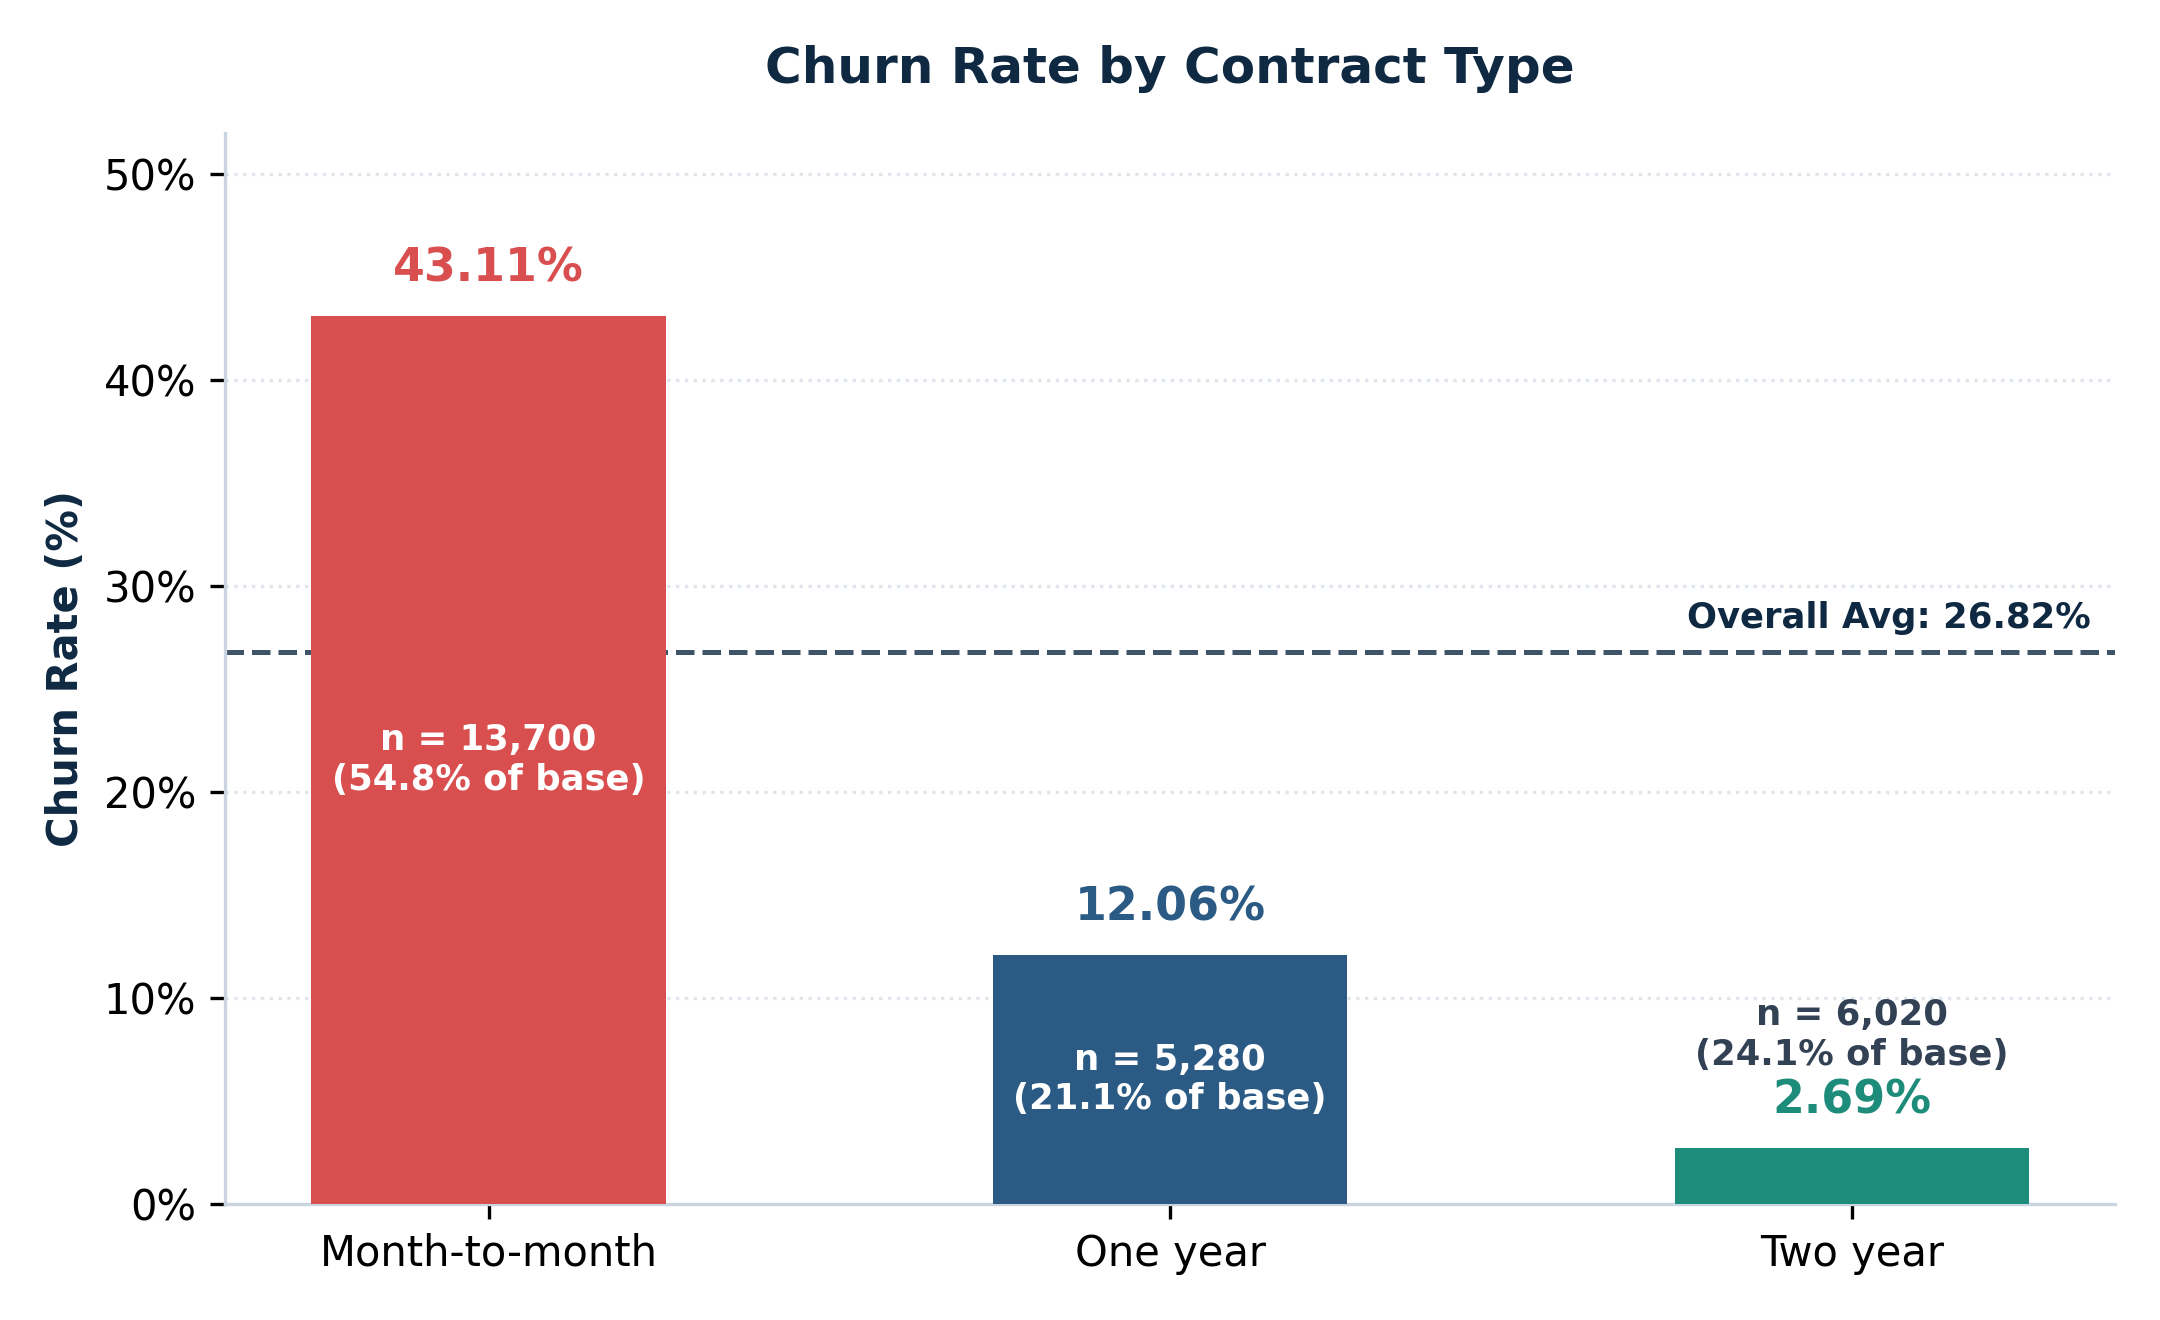

In [4]:
# ---------------------------------------------------------
# CHART 4: Contract Structure (Not included in Presentation)
# ---------------------------------------------------------
con_order = ['Month-to-month', 'One year', 'Two year']
con_grp = df.groupby('Contract').agg(
    Count=('CustomerID', 'count'),
    ChurnRate=('Churn_num', lambda x: x.mean() * 100)
).reindex(con_order)

fig, ax = plt.subplots(figsize=(7.2, 4.4), dpi=300)
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

c_colors = [CORAL, SLATE, TEAL]
ax.bar(con_order, con_grp['ChurnRate'], color=c_colors, width=0.52, zorder=3)

for i, (rate, cnt) in enumerate(zip(con_grp['ChurnRate'], con_grp['Count'])):
    ax.text(i, rate + 1.2, f'{rate:.2f}%', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=c_colors[i])
    ax.text(i, rate / 2 if rate > 8 else rate + 5.5,
            f'n = {cnt:,}\n({cnt/len(df)*100:.1f}% of base)',
            ha='center', va='center', fontsize=8.5, fontweight='bold',
            color='white' if rate > 8 else '#334155')

ax.axhline(26.82, color=NAVY, linestyle='--', linewidth=1.2, alpha=0.8)
ax.text(2.35, 27.6, 'Overall Avg: 26.82%', ha='right', va='bottom',
        fontsize=8.5, fontweight='bold', color=NAVY)
ax.set_ylim(0, 52)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Churn Rate (%)', fontsize=10, fontweight='bold', color=NAVY)
ax.set_title('Churn Rate by Contract Type', fontsize=12, fontweight='bold', color=NAVY, pad=12)
ax.tick_params(axis='x', labelsize=10)
ax.grid(axis='y', linestyle=':', alpha=0.6, color='#CBD5E1')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('charts/contract.png', dpi=300, facecolor=BG)
plt.close()

display(Image('charts/contract.png'))

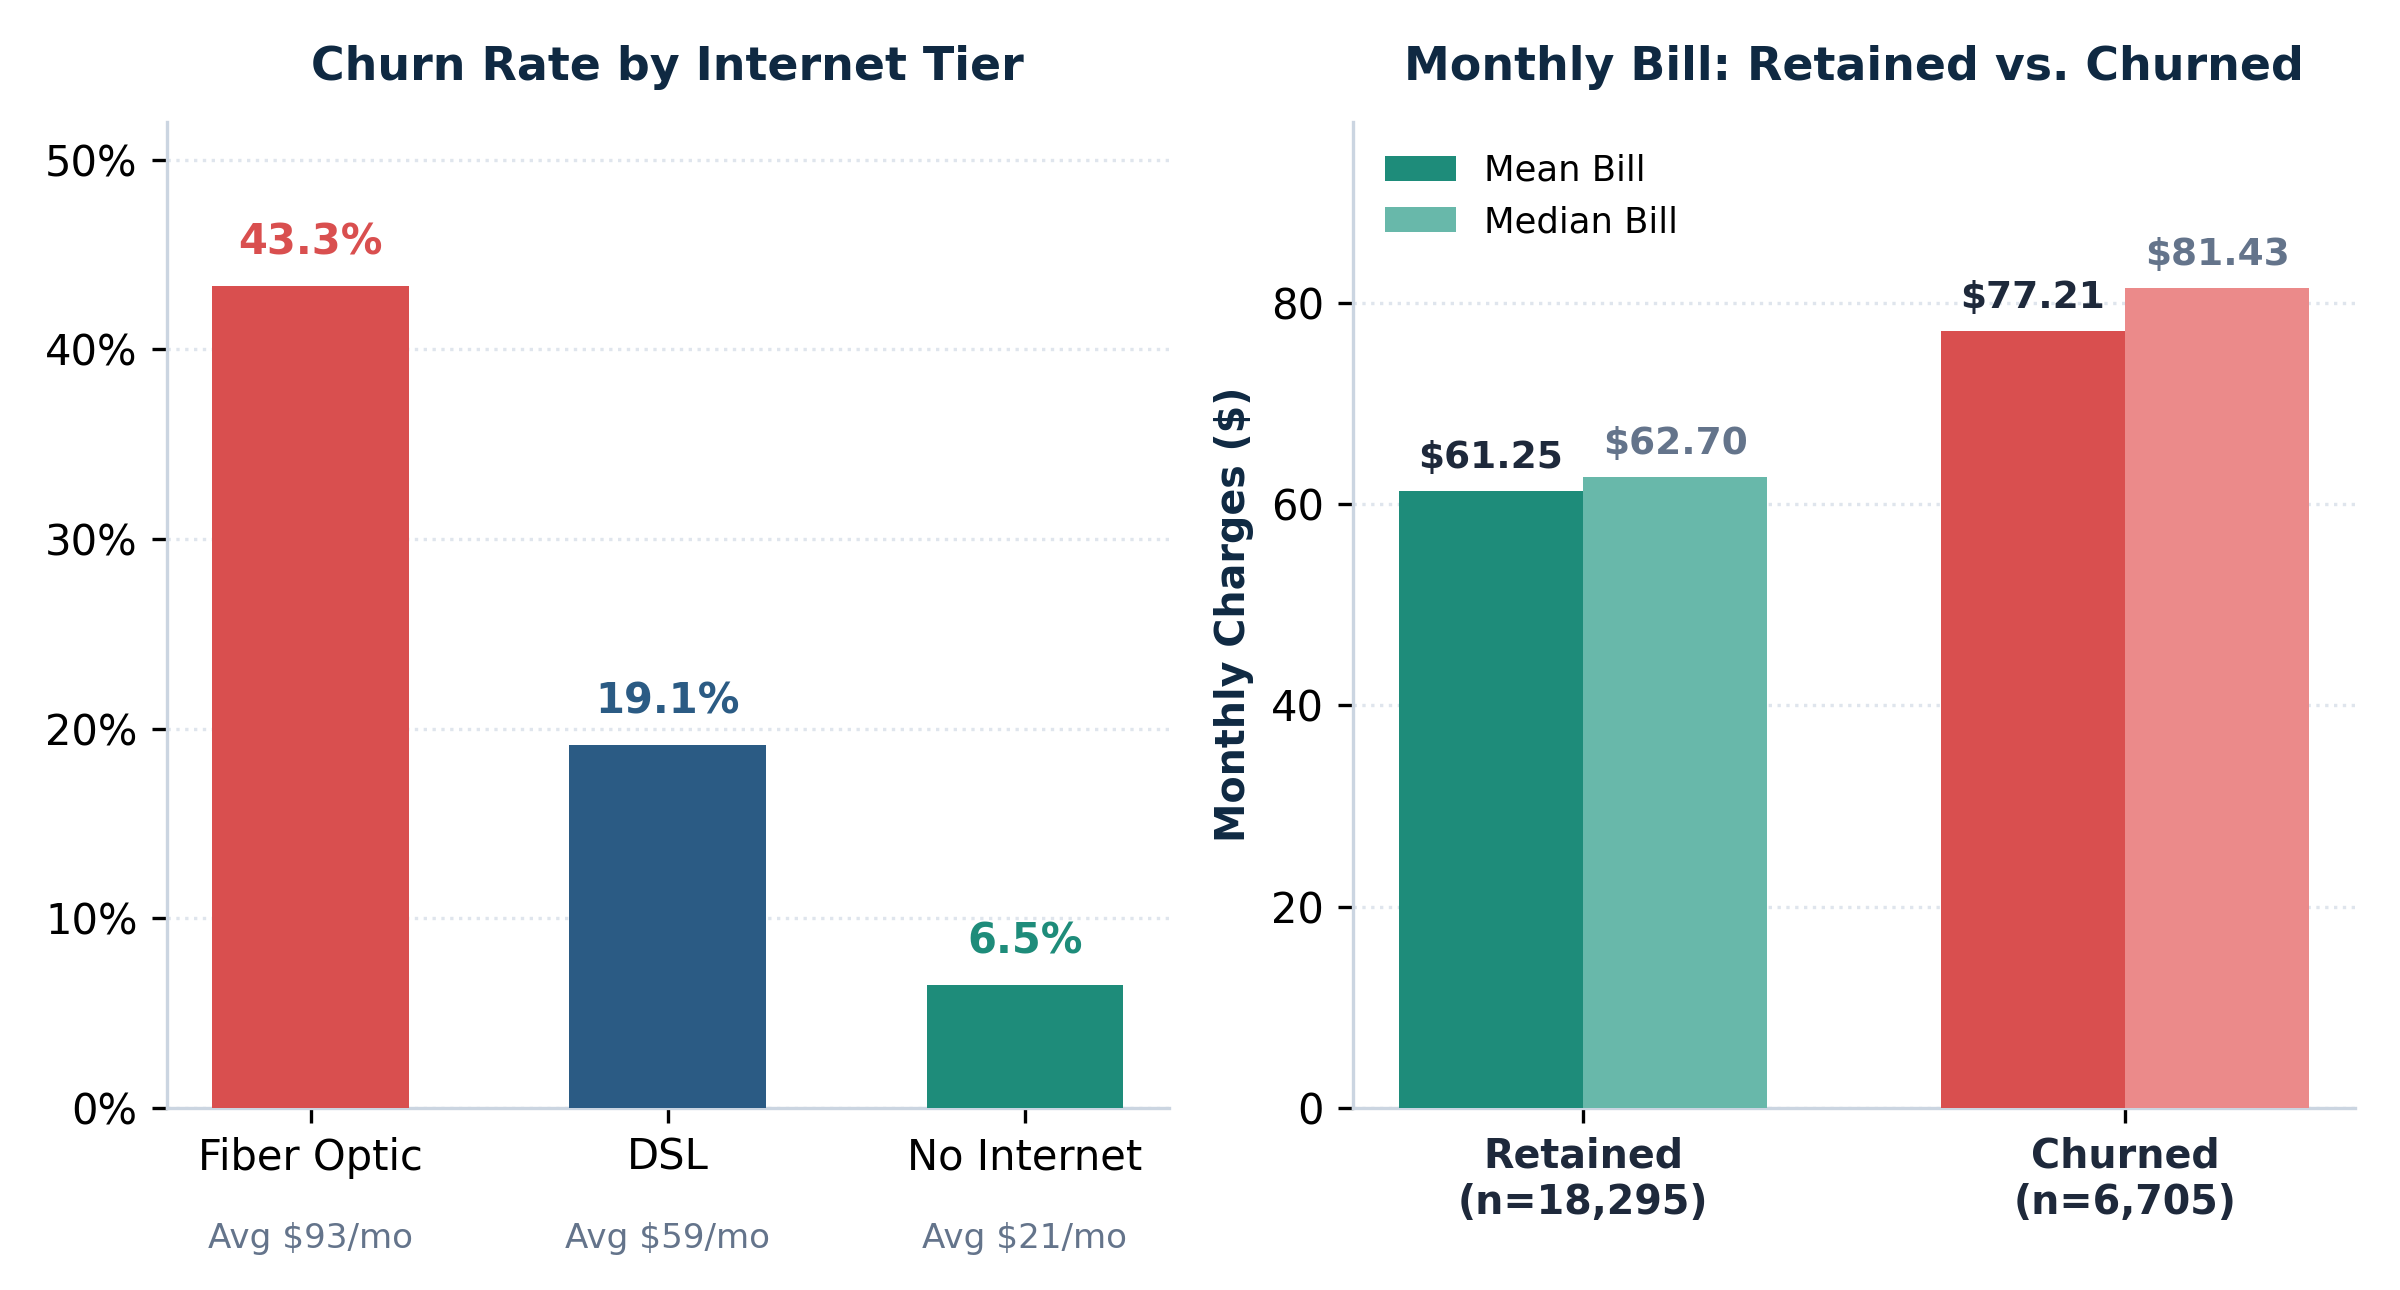

In [5]:
# ---------------------------------------------------------
# CHART 5: Internet Tier & Monthly Charges Paradox (Not included in presentation)
# ---------------------------------------------------------
inet_order = ['Fiber optic', 'DSL', 'No']
inet_labels = ['Fiber Optic', 'DSL', 'No Internet']
inet_grp = df.groupby('InternetService').agg(
    Count=('CustomerID', 'count'),
    ChurnRate=('Churn_num', lambda x: x.mean() * 100),
    MeanBill=('MonthlyCharges', 'mean')
).reindex(inet_order)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.0, 4.3), dpi=300)
fig.patch.set_facecolor(BG)

# Left panel: Churn by Internet Service
ax1.set_facecolor(BG)
ic = [CORAL, SLATE, TEAL]
ax1.bar(inet_labels, inet_grp['ChurnRate'], color=ic, width=0.55, zorder=3)
for i, (r, b) in enumerate(zip(inet_grp['ChurnRate'], inet_grp['MeanBill'])):
    ax1.text(i, r + 1.2, f'{r:.1f}%', ha='center', va='bottom',
             fontsize=10, fontweight='bold', color=ic[i])
    ax1.text(i, -6.0, f'Avg ${b:.0f}/mo', ha='center', va='top', fontsize=8.2, color=GRAY)
ax1.set_ylim(0, 52)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter())
ax1.set_title('Churn Rate by Internet Tier', fontsize=11, fontweight='bold', color=NAVY, pad=10)
ax1.grid(axis='y', linestyle=':', alpha=0.6, color='#CBD5E1')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Right panel: Mean vs. Median Monthly Charges by Churn
ax2.set_facecolor(BG)
mc_stats = df.groupby('Churn')['MonthlyCharges'].agg(['mean', 'median']).reindex(['No', 'Yes'])
x = np.arange(2)
w = 0.34
ax2.bar(x - w/2, mc_stats['mean'], width=w, color=[TEAL, CORAL], label='Mean Bill', zorder=3)
ax2.bar(x + w/2, mc_stats['median'], width=w, color=['#68B8AA', '#EB8A8A'], label='Median Bill', zorder=3)
for i in range(2):
    ax2.text(x[i] - w/2, mc_stats['mean'].iloc[i] + 1.5, f"${mc_stats['mean'].iloc[i]:.2f}",
             ha='center', va='bottom', fontsize=9, fontweight='bold', color='#1E293B')
    ax2.text(x[i] + w/2, mc_stats['median'].iloc[i] + 1.5, f"${mc_stats['median'].iloc[i]:.2f}",
             ha='center', va='bottom', fontsize=9, fontweight='bold', color=GRAY)
ax2.set_xticks(x)
ax2.set_xticklabels(['Retained\n(n=18,295)', 'Churned\n(n=6,705)'],
                    fontsize=9.5, fontweight='bold', color='#1E293B')
ax2.set_ylim(0, 98)
ax2.set_ylabel('Monthly Charges ($)', fontsize=9.5, fontweight='bold', color=NAVY)
ax2.set_title('Monthly Bill: Retained vs. Churned', fontsize=11, fontweight='bold', color=NAVY, pad=10)
ax2.legend(frameon=False, fontsize=8.5, loc='upper left')
ax2.grid(axis='y', linestyle=':', alpha=0.6, color='#CBD5E1')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.subplots_adjust(bottom=0.18, wspace=0.28)
plt.tight_layout()
plt.savefig('charts/fiber_pricing.png', dpi=300, facecolor=BG)
plt.close()


display(Image('charts/fiber_pricing.png'))

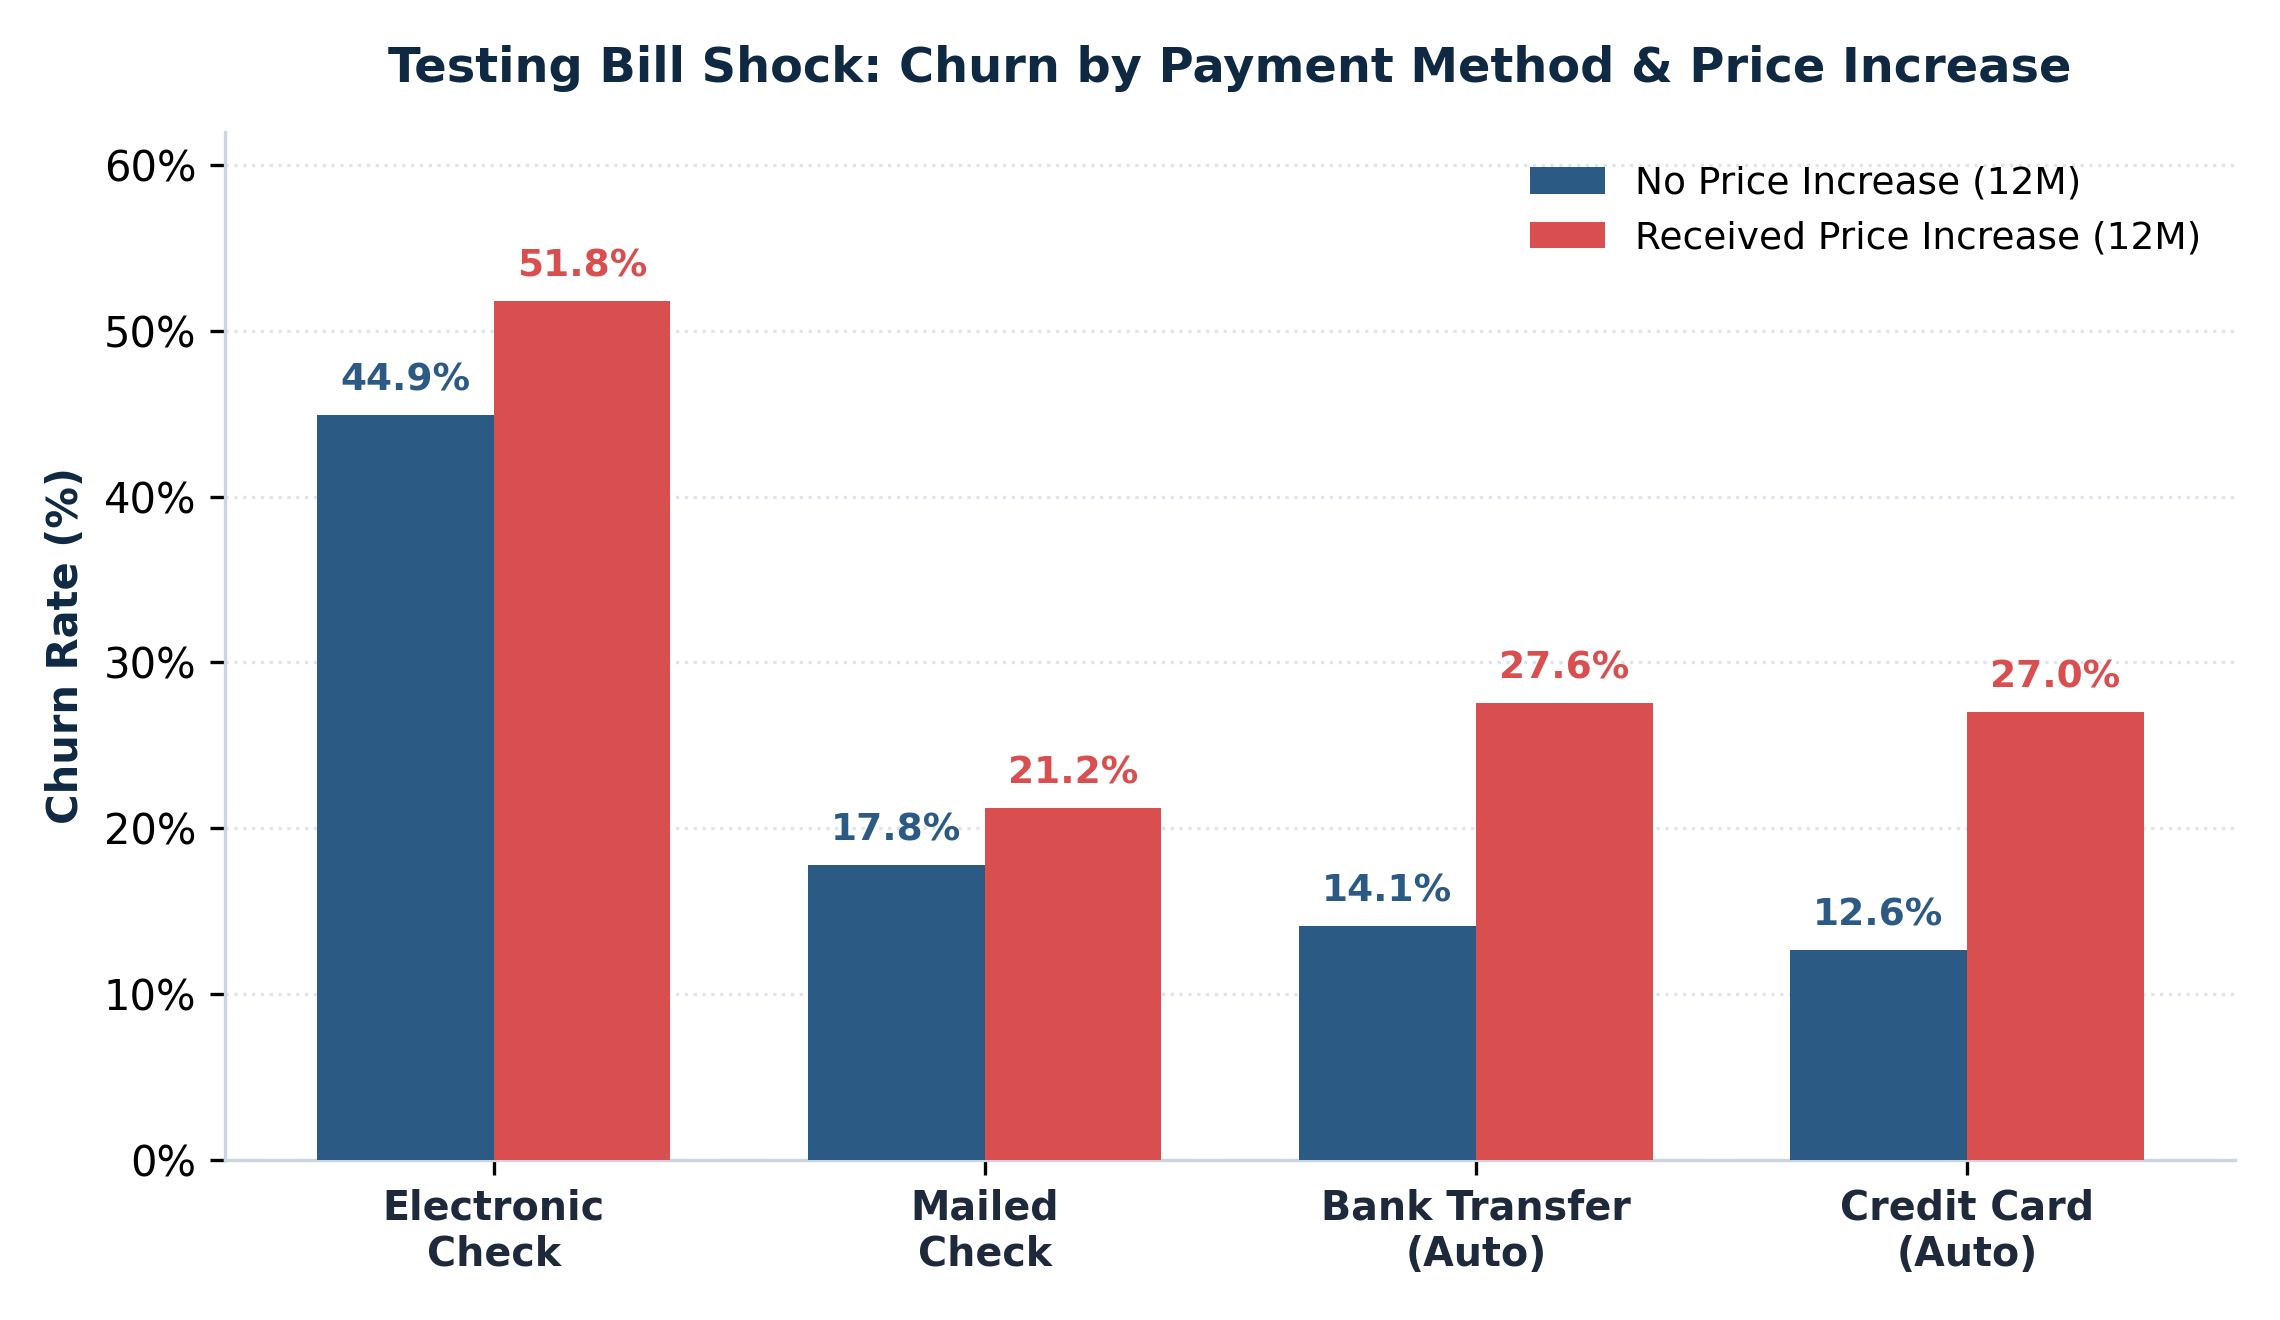

In [6]:
# ---------------------------------------------------------
# CHART 6 (Slide 10): Testing Bill Shock (PaymentMethod x PriceIncrease12M)
# ---------------------------------------------------------
pm_order = ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
pm_short = ['Electronic\nCheck', 'Mailed\nCheck', 'Bank Transfer\n(Auto)', 'Credit Card\n(Auto)']
ct_pi = df.pivot_table(
    index='PaymentMethod', columns='PriceIncrease12M', values='Churn_num', aggfunc='mean'
).reindex(pm_order) * 100

fig, ax = plt.subplots(figsize=(7.6, 4.4), dpi=300)
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

x = np.arange(len(pm_order))
w = 0.36
ax.bar(x - w/2, ct_pi['No'], width=w, color=SLATE, label='No Price Increase (12M)', zorder=3)
ax.bar(x + w/2, ct_pi['Yes'], width=w, color=CORAL, label='Received Price Increase (12M)', zorder=3)

for i in range(len(pm_order)):
    ax.text(x[i] - w/2, ct_pi['No'].iloc[i] + 1.0, f"{ct_pi['No'].iloc[i]:.1f}%",
            ha='center', va='bottom', fontsize=9, fontweight='bold', color=SLATE)
    ax.text(x[i] + w/2, ct_pi['Yes'].iloc[i] + 1.0, f"{ct_pi['Yes'].iloc[i]:.1f}%",
            ha='center', va='bottom', fontsize=9, fontweight='bold', color=CORAL)

ax.set_xticks(x)
ax.set_xticklabels(pm_short, fontsize=9.5, fontweight='bold', color='#1E293B')
ax.set_ylim(0, 62)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Churn Rate (%)', fontsize=10, fontweight='bold', color=NAVY)
ax.set_title('Testing Bill Shock: Churn by Payment Method & Price Increase',
             fontsize=11.5, fontweight='bold', color=NAVY, pad=12)
ax.legend(frameon=False, fontsize=9, loc='upper right')
ax.grid(axis='y', linestyle=':', alpha=0.6, color='#CBD5E1')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('charts/bill_shock.png', dpi=300, facecolor=BG)
plt.close()



display(Image('charts/bill_shock.png'))

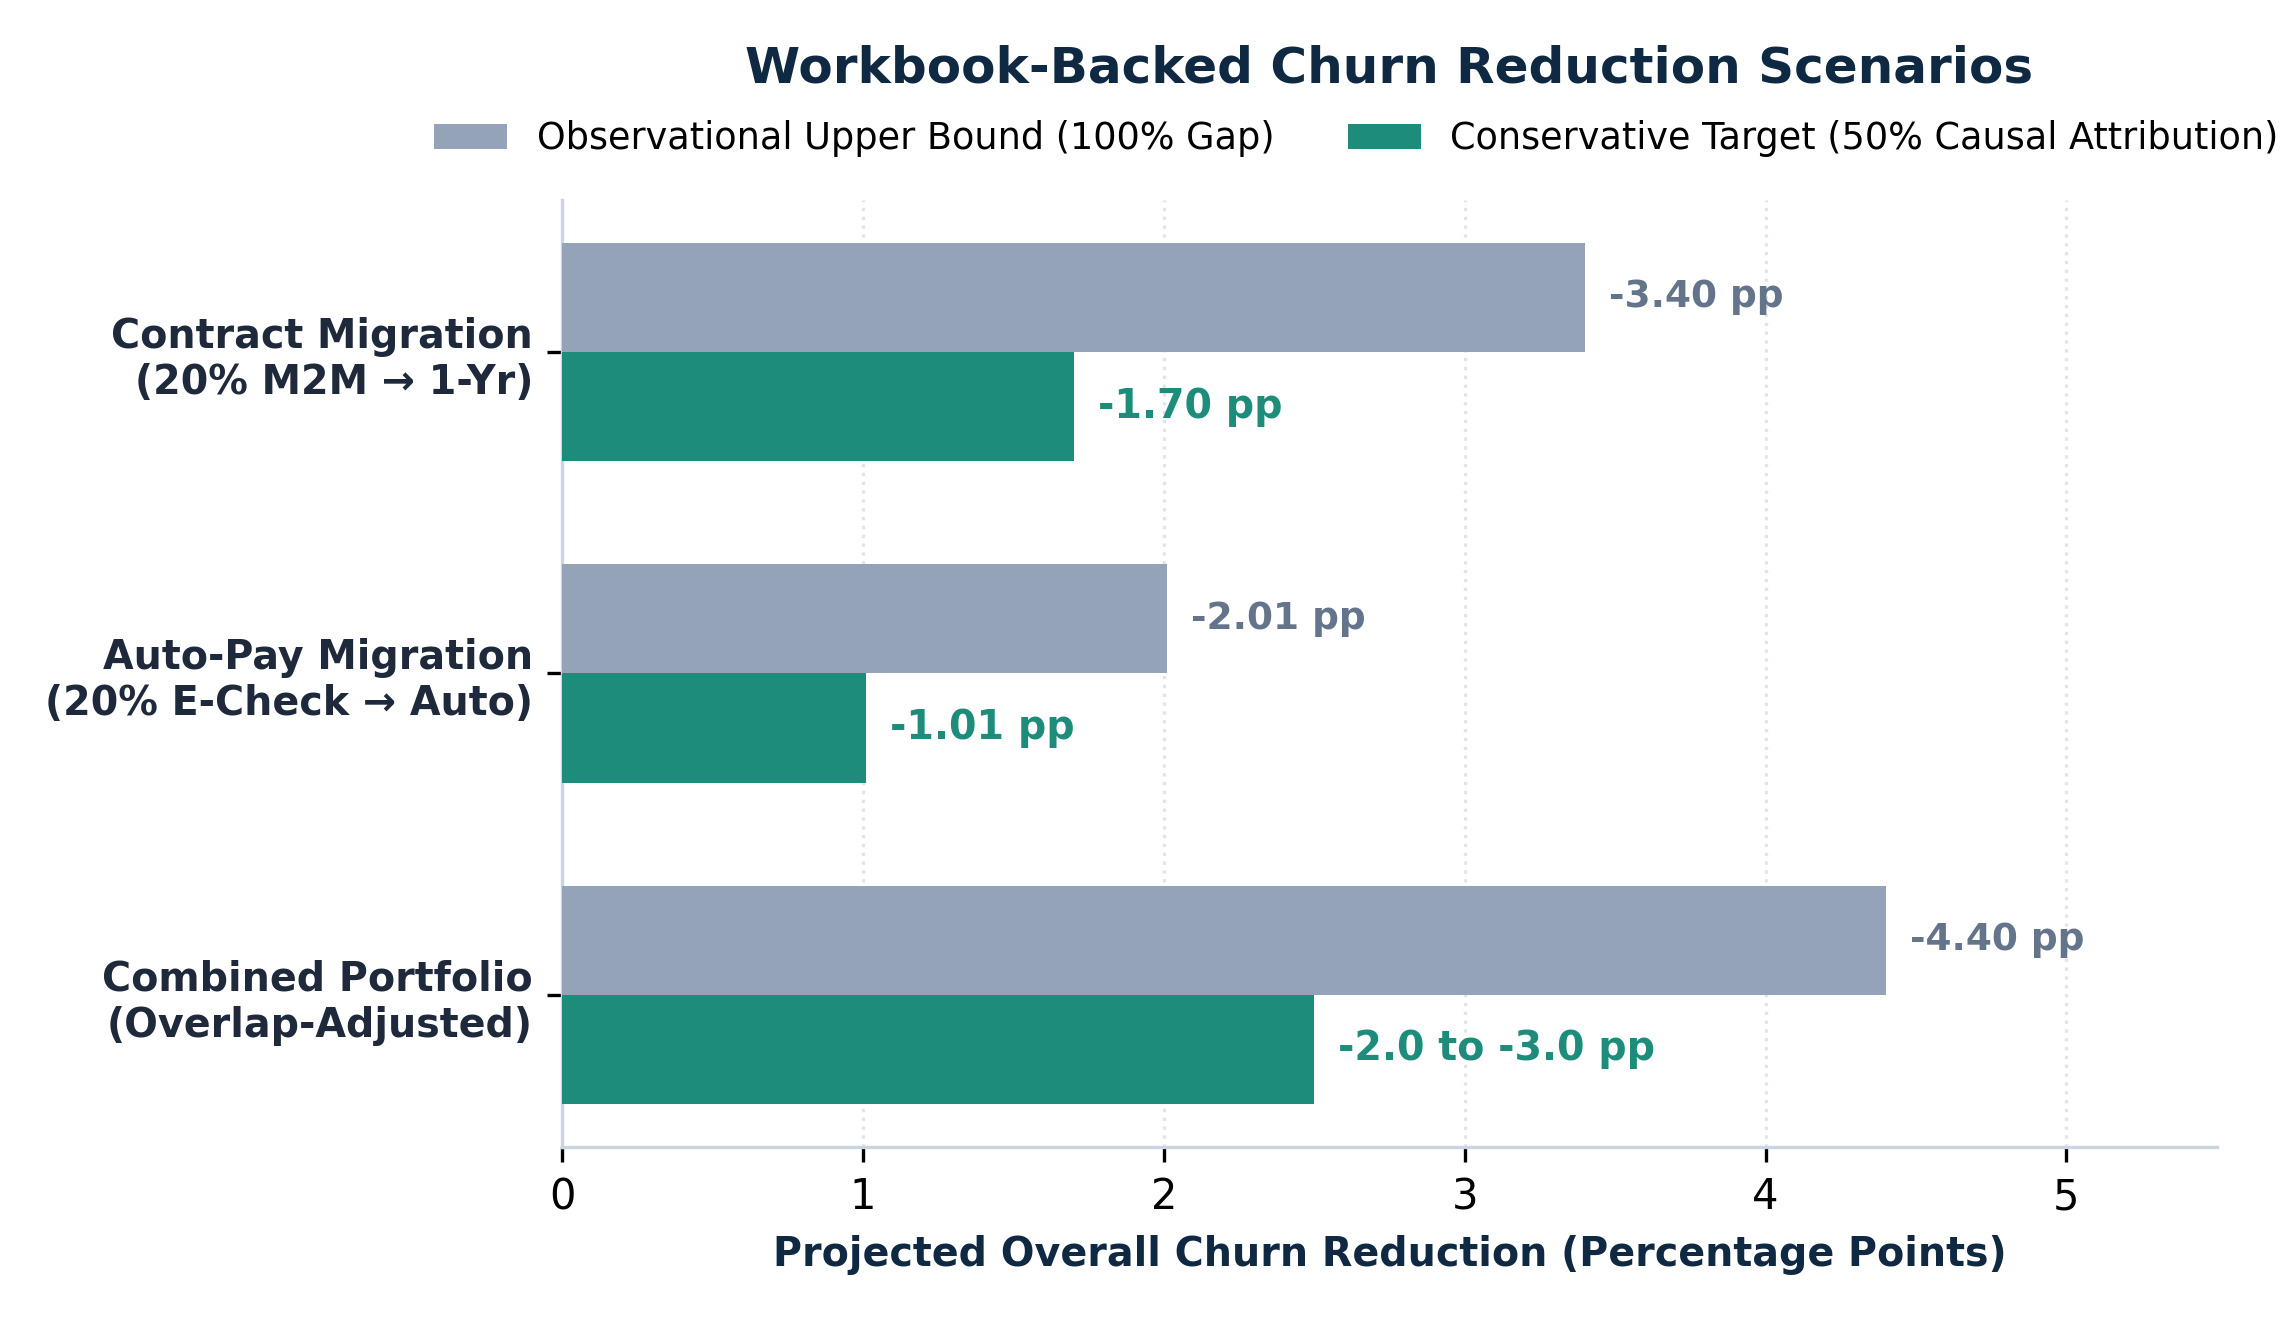

In [7]:
# ---------------------------------------------------------
# CHART 9 (Slide 12): Grounded Churn Reduction Scenarios
# ---------------------------------------------------------
scenarios = [
    'Contract Migration\n(20% M2M → 1-Yr)',
    'Auto-Pay Migration\n(20% E-Check → Auto)',
    'Combined Portfolio\n(Overlap-Adjusted)'
]
upper_bound = [3.40, 2.01, 4.40]   # 100% observed gap (combined discounted for 6,477 overlap)
conservative = [1.70, 1.01, 2.50]  # 50% causal attribution (midpoint of 2.0–3.0 pp)

fig, ax = plt.subplots(figsize=(7.6, 4.4), dpi=300)
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

y = np.arange(len(scenarios))[::-1]
h = 0.34
ax.barh(y + h/2, upper_bound, height=h, color='#94A3B8',
        label='Observational Upper Bound (100% Gap)', zorder=3)
ax.barh(y - h/2, conservative, height=h, color=TEAL,
        label='Conservative Target (50% Causal Attribution)', zorder=3)

for i in range(len(scenarios)):
    ax.text(upper_bound[i] + 0.08, y[i] + h/2, f'-{upper_bound[i]:.2f} pp',
            ha='left', va='center', fontsize=9, fontweight='bold', color=GRAY)
    lbl = '-2.0 to -3.0 pp' if i == 2 else f'-{conservative[i]:.2f} pp'
    ax.text(conservative[i] + 0.08, y[i] - h/2, lbl,
            ha='left', va='center', fontsize=9.5, fontweight='bold', color=TEAL)

ax.set_yticks(y)
ax.set_yticklabels(scenarios, fontsize=9.5, fontweight='bold', color='#1E293B')
ax.set_xlim(0, 5.5)
ax.set_xlabel('Projected Overall Churn Reduction (Percentage Points)',
              fontsize=9.5, fontweight='bold', color=NAVY)
ax.set_title('Workbook-Backed Churn Reduction Scenarios',
             fontsize=12, fontweight='bold', color=NAVY, pad=28)
ax.legend(frameon=False, fontsize=8.8, loc='lower center',
          bbox_to_anchor=(0.48, 1.01), ncol=2)
ax.grid(axis='x', linestyle=':', alpha=0.6, color='#CBD5E1')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('charts/scenarios.png', dpi=300, facecolor=BG)
plt.close()

display(Image('charts/scenarios.png'))

In [8]:
# ---------------------------------------------------------
# (Slide 13): Four Evidence-Informed Retention Initiatives
# ---------------------------------------------------------

def calculate_churn(data, segment_name):
    total_customers = len(data)

    churned = (data["Churn"] == "Yes").sum()
    retained = (data["Churn"] == "No").sum()

    churn_rate = (churned / total_customers) * 100
    retention_rate = (retained / total_customers) * 100

    return {
        "Segment": segment_name,
        "Total Customers": total_customers,
        "Churned Customers": churned,
        "Retained Customers": retained,
        "Churn Rate (%)": round(churn_rate, 2),
        "Retention Rate (%)": round(retention_rate, 2)
    }



In [9]:

# Filter Fiber Optic + Month-to-Month customers
fiber_m2m = df[
    (df["InternetService"] == "Fiber optic") &
    (df["Contract"] == "Month-to-month")
]

fiber_results = calculate_churn(
    fiber_m2m,
    "Fiber + Month-to-Month"
)

print("RECOMMENDATION 1: FIBER M2M LOCK-IN")
print(pd.DataFrame([fiber_results]).to_string(index=False))

# Compare contract types
contract_results = []

for contract in df["Contract"].unique():
    segment = df[df["Contract"] == contract]
    contract_results.append(
        calculate_churn(segment, contract)
    )

contract_df = pd.DataFrame(contract_results)

print("\nChurn by Contract Type:")
print(contract_df.to_string(index=False))


RECOMMENDATION 1: FIBER M2M LOCK-IN
               Segment  Total Customers  Churned Customers  Retained Customers  Churn Rate (%)  Retention Rate (%)
Fiber + Month-to-Month             7403               4198                3205           56.71               43.29

Churn by Contract Type:
       Segment  Total Customers  Churned Customers  Retained Customers  Churn Rate (%)  Retention Rate (%)
Month-to-month            13700               5906                7794           43.11               56.89
      Two year             6020                162                5858            2.69               97.31
      One year             5280                637                4643           12.06               87.94


In [10]:

# Customers with Online Security
security_yes = df[df["OnlineSecurity"] == "Yes"]

# Customers without Online Security
security_no = df[df["OnlineSecurity"] == "No"]

security_results = [
    calculate_churn(security_yes, "Online Security - Yes"),
    calculate_churn(security_no, "Online Security - No")
]

security_df = pd.DataFrame(security_results)

print("RECOMMENDATION 2: ONLINE SECURITY")
print(security_df.to_string(index=False))

# Calculate percentage-point difference
difference = (
    security_df.loc[
        security_df["Segment"] == "Online Security - No",
        "Churn Rate (%)"
    ].iloc[0]
    -
    security_df.loc[
        security_df["Segment"] == "Online Security - Yes",
        "Churn Rate (%)"
    ].iloc[0]
)

print("\nChurn Rate Difference:", round(difference, 2), "percentage points")


RECOMMENDATION 2: ONLINE SECURITY
              Segment  Total Customers  Churned Customers  Retained Customers  Churn Rate (%)  Retention Rate (%)
Online Security - Yes             7233               1190                6043           16.45               83.55
 Online Security - No            12255               5159                7096           42.10               57.90

Churn Rate Difference: 25.65 percentage points


In [11]:

# Electronic check customers
electronic_check = df[
    df["PaymentMethod"] == "Electronic check"
]

# Automatic payment customers
automatic_payment = df[
    df["PaymentMethod"].isin([
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ])
]

payment_results = [
    calculate_churn(electronic_check, "Electronic Check"),
    calculate_churn(automatic_payment, "Automatic Payment")
]

payment_df = pd.DataFrame(payment_results)

print("RECOMMENDATION 3: AUTOMATIC PAYMENT")
print(payment_df.to_string(index=False))

# Calculate churn difference
electronic_churn = payment_df.iloc[0]["Churn Rate (%)"]
automatic_churn = payment_df.iloc[1]["Churn Rate (%)"]

payment_difference = electronic_churn - automatic_churn

print("\nChurn Difference:",
      round(payment_difference, 2),
      "percentage points")


RECOMMENDATION 3: AUTOMATIC PAYMENT
          Segment  Total Customers  Churned Customers  Retained Customers  Churn Rate (%)  Retention Rate (%)
 Electronic Check             8333               3876                4457           46.51               53.49
Automatic Payment            10876               1772                9104           16.29               83.71

Churn Difference: 30.22 percentage points


In [12]:

# Group support tickets into 0, 1, 2, and 3+
df["Ticket_Group"] = np.where(
    df["SupportTickets12M"] >= 3,
    "3+ Tickets",
    df["SupportTickets12M"].astype(str)
)

# Calculate churn by support-ticket group
ticket_results = []

for group in ["0", "1", "2", "3+ Tickets"]:
    segment = df[df["Ticket_Group"] == group]

    ticket_results.append(
        calculate_churn(segment, group)
    )

ticket_df = pd.DataFrame(ticket_results)

print("RECOMMENDATION 4A: SUPPORT TICKETS")
print(ticket_df.to_string(index=False))


# Compare senior and non-senior customers
senior = df[df["SeniorCitizen"] == 1]
non_senior = df[df["SeniorCitizen"] == 0]

senior_results = [
    calculate_churn(senior, "Senior Citizens"),
    calculate_churn(non_senior, "Non-Senior Citizens")
]

senior_df = pd.DataFrame(senior_results)

print("\nRECOMMENDATION 4B: SENIOR CUSTOMERS")
print(senior_df.to_string(index=False))


RECOMMENDATION 4A: SUPPORT TICKETS
   Segment  Total Customers  Churned Customers  Retained Customers  Churn Rate (%)  Retention Rate (%)
         0            13554               3150               10404           23.24               76.76
         1             7216               1968                5248           27.27               72.73
         2             2935                985                1950           33.56               66.44
3+ Tickets             1295                602                 693           46.49               53.51

RECOMMENDATION 4B: SENIOR CUSTOMERS
            Segment  Total Customers  Churned Customers  Retained Customers  Churn Rate (%)  Retention Rate (%)
    Senior Citizens             4004               1749                2255           43.68               56.32
Non-Senior Citizens            20996               4956               16040           23.60               76.40


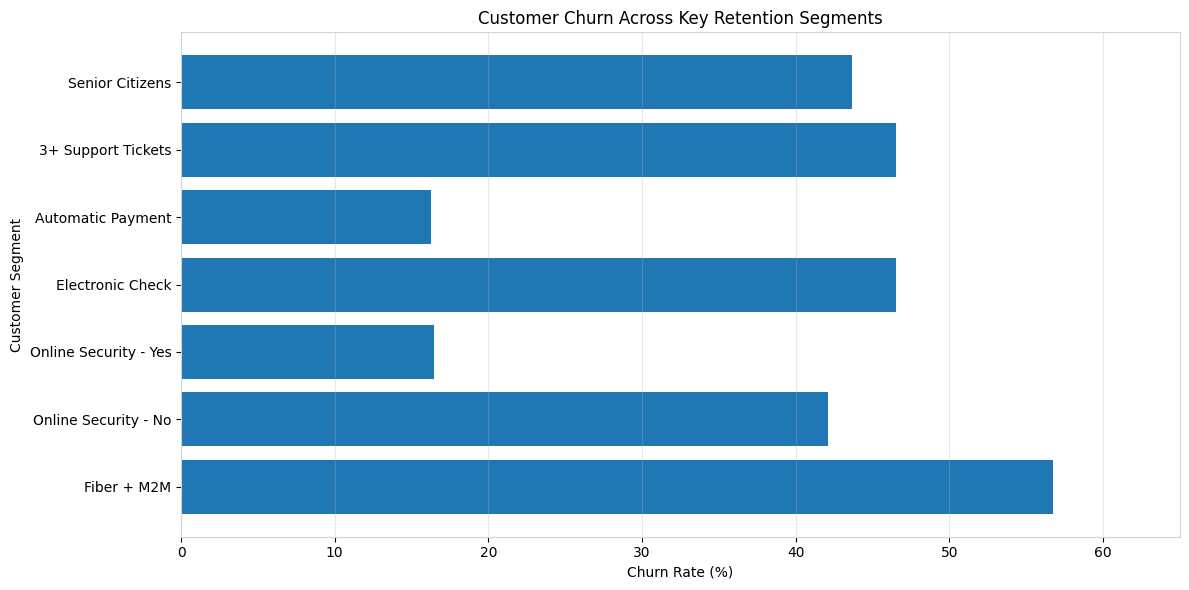

In [13]:

# ---------------------------------------------------------
# CHART 10: Grounded Churn Reduction Scenarios (Not included in presentation)
# ---------------------------------------------------------
# Prepare key churn comparisons
comparison = pd.DataFrame({
    "Segment": [
        "Fiber + M2M",
        "Online Security - No",
        "Online Security - Yes",
        "Electronic Check",
        "Automatic Payment",
        "3+ Support Tickets",
        "Senior Citizens"
    ],
    "Churn Rate": [
        56.71,
        42.10,
        16.45,
        46.51,
        16.29,
        46.49,
        43.68
    ]
})

# Plot comparison
plt.figure(figsize=(12, 6))

plt.barh(
    comparison["Segment"],
    comparison["Churn Rate"]
)

plt.xlabel("Churn Rate (%)")
plt.ylabel("Customer Segment")
plt.title("Customer Churn Across Key Retention Segments")

plt.xlim(0, 65)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
